# Station time series and storm index

This shows how wind and snow water equivalent from the weather stations are compared with $\gamma_{snow}$ for each date pair. 

In [2]:
import numpy as np
import xarray as xr
import pandas as pd
import rioxarray  
from rasterio.enums import Resampling
import matplotlib.pyplot as plt
from seaborn import set_theme
set_theme()

import sys
import os
from pathlib import Path

# import from this repo 
project_root = str(Path(os.getcwd()).parent)
if project_root not in sys.path:
    sys.path.append(project_root)

%load_ext autoreload
%autoreload 2
from scripts.stations import read_mesowest, read_snotel, event_wind_by_pair, pair_metrics

First, we setup logging to get useful information and error messages. 

In [3]:
import logging

logging.basicConfig(
    level=logging.INFO,
    format='%(asctime)s - %(levelname)s - %(message)s',
    force=True 
)

Open the data cubes that were saved by the previous notebook. 

In [4]:
data_dir = "../data/"
track = 19
frame = 21

# nisar_20m = xr.open_zarr(data_dir + f'nisar/zarrs/track{str(track).zfill(3)}_frame{str(frame).zfill(3)}/snow_20m.zarr').isel(pair=slice(1, -2))
nisar_80m = xr.open_zarr(data_dir + f'nisar/zarrs/all_pairs/track{str(track).zfill(3)}/coherence_80m.zarr').isel(pair=slice(1, -2))


/tmp/ipykernel_263924/406435300.py:6: RuntimeWarning: Failed to open Zarr store with consolidated metadata, but successfully read with non-consolidated metadata. This is typically much slower for opening a dataset. To silence this warning, consider:
1. Consolidating metadata in this existing store with zarr.consolidate_metadata().
2. Explicitly setting consolidated=False, to avoid trying to read consolidate metadata, or
3. Explicitly setting consolidated=True, to raise an error in this case instead of falling back to try reading non-consolidated metadata.
  nisar_80m = xr.open_zarr(data_dir + f'nisar/zarrs/all_pairs/track{str(track).zfill(3)}/coherence_80m.zarr').isel(pair=slice(1, -2))


The start and end time of each date pair are stored in the cube. 

In [5]:
starts = nisar_80m['start'].values
ends = nisar_80m['end'].values
unique_dates = np.unique(np.concatenate([starts, ends]))

In [8]:
# Sorted list of every acquisition date that appears in any pair
dates = np.unique(np.concatenate([starts, ends]))

# For each pair, find the index of its start date, then check whether
# its end date is the very next acquisition (= nearest neighbor)
i_start = np.searchsorted(dates, starts)
next_date = dates[np.minimum(i_start + 1, len(dates) - 1)]  # clip avoids index overflow on the last date
is_nn = (ends == next_date) & (i_start + 1 < len(dates))

nn_idx = np.flatnonzero(is_nn)                      # integer positions along the pair dimension
nn_pairs = list(zip(starts[nn_idx], ends[nn_idx]))

nisar_80m = nisar_80m.isel(pair=nn_idx)

Load the wind speed and air temperature from the MesoWest stations. The time zone offset needs to match the cubes. 

In [9]:
wind_files = sorted(Path(data_dir + 'stations/mesowest/').glob('*.csv'))
wind_names = {
    'SOSC2': 'schofield_pass',
    'CACNM': 'cinnamon_mtn',
    'CASCP': 'irwins_ridge',
}

wind = read_mesowest(wind_files, wind_names, utc_offset_hours=-7)

/bsuhome/julialober/nisar_snow_coherence/scripts/stations.py:49: DtypeWarning: Columns (0: pressure_set_1, 1: air_temp_set_1, 2: relative_humidity_set_1, 3: wind_speed_set_1, 4: wind_direction_set_1, 5: wind_gust_set_1, 6: snow_depth_set_1, 7: solar_radiation_set_1, 8: soil_temp_set_1, 9: precip_accum_set_1, 10: snow_interval_set_1, 11: T_water_temp_set_1, 12: evapotranspiration_set_1) have mixed types. Specify dtype option on import or set low_memory=False.
  ds = pd.read_csv(f, comment='#')
/bsuhome/julialober/nisar_snow_coherence/scripts/stations.py:49: DtypeWarning: Columns (0: air_temp_set_1, 1: relative_humidity_set_1, 2: wind_speed_set_1, 3: wind_speed_set_2, 4: wind_direction_set_1, 5: wind_direction_set_2, 6: wind_gust_set_1, 7: solar_radiation_set_1) have mixed types. Specify dtype option on import or set low_memory=False.
  ds = pd.read_csv(f, comment='#')


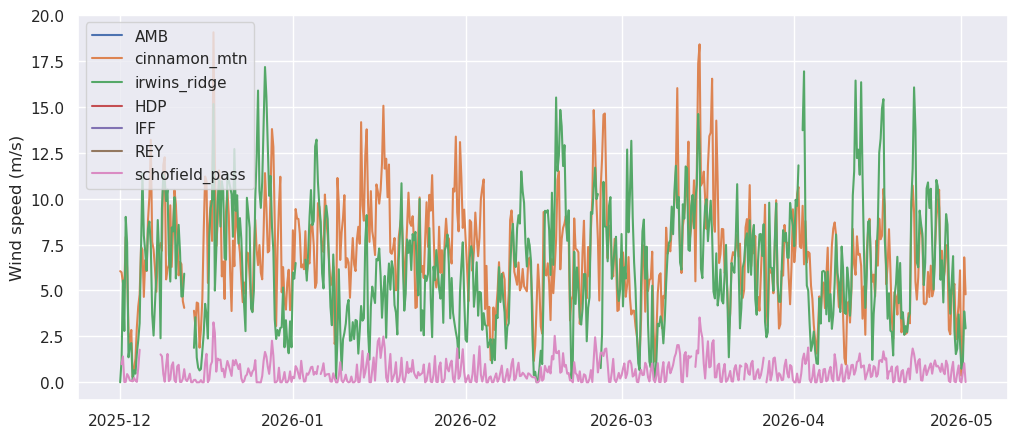

In [10]:
sub = wind['wind_speed'].sel(datetime=slice('2025-12-01', '2026-05-01'))
fig, ax = plt.subplots(figsize=(12, 5))
for sid in sub.station_id.values:
    s = sub.sel(station_id=sid).resample(datetime='6h').mean()
    ax.plot(s.datetime, s, label=str(s.station_name.values))
ax.set_ylabel(f"Wind speed ({wind['wind_speed'].attrs['units']})")
ax.legend()

Load the snow water equivalent and air temperature from the SNOTEL stations. 

In [11]:
snotel_files = sorted(Path(data_dir + 'stations/snotel/').glob('*WATERYEAR*.csv'))
snotel_names = {
    '1141': 'upper_taylor',
    '380':  'butte',
    '1326': 'castle_peak',
    '737':  'schofield_pass',
}

swe = read_snotel(snotel_files, snotel_names, utc_offset_hours=-7)

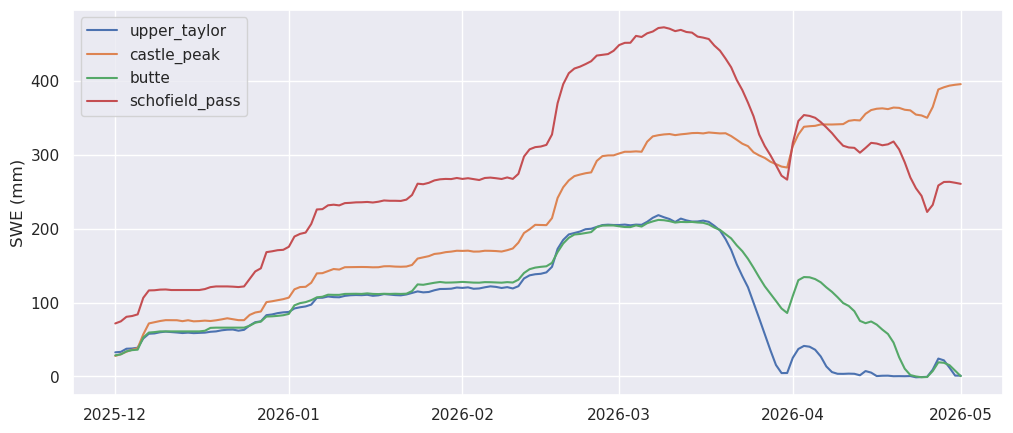

In [12]:
sub = swe['swe'].sel(datetime=slice('2025-12-01', '2026-05-01'))
fig, ax = plt.subplots(figsize=(12, 5))
for sid in sub.station_id.values:
    s = sub.sel(station_id=sid).resample(datetime='1d').mean()
    ax.plot(s.datetime, s, label=str(s.station_name.values))
ax.set_ylabel(f"SWE (mm)")
ax.legend()

Plot SWE and wind together, with the NISAR acquisition dates in orange. 

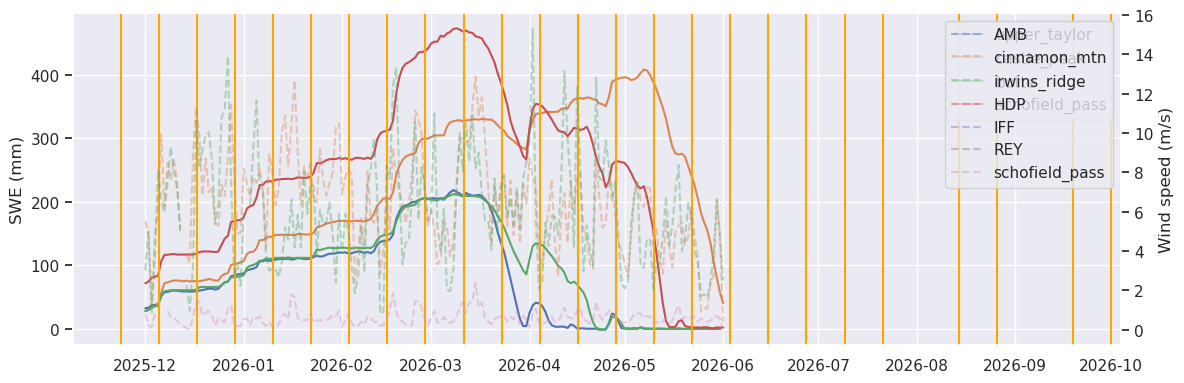

In [13]:
t0 = np.datetime64('2025-12-01')
t1 = np.datetime64('2026-06-01')

swe_plot = swe.sel(datetime=slice(t0, t1)).resample(datetime='1d').mean()
wind_plot = wind['wind_speed'].sel(datetime=slice(t0, t1)).resample(datetime='1d').mean()

fig, ax = plt.subplots(figsize=(12, 4))
ax2 = ax.twinx()

for sid in swe_plot.station_id.values:
    station = swe_plot['swe'].sel(station_id=sid)
    ax.plot(station.datetime, station, label=str(station.station_name.values))
ax.set_ylabel('SWE (mm)')
ax.legend()

for sid in wind_plot.station_id.values:
    station = wind_plot.sel(station_id=sid)
    ax2.plot(station.datetime, station, alpha=0.4, linestyle='--', label=str(station.station_name.values))
ax2.set_ylabel('Wind speed (m/s)')
ax2.grid(False)
ax2.legend(loc='upper right')

[ax.axvline(d, c='orange') for d in unique_dates]

plt.tight_layout()
plt.show()

Limit to just the dry snow pairs for this part. 

In [70]:
nisar_20m_dry = nisar_20m.sel(start=slice("2025-12-01", "2026-02-20"))
nisar_80m_dry = nisar_80m.sel(start=slice("2025-12-01", "2026-02-20"))

dry_starts = nisar_80m_dry['start'].values
dry_ends = nisar_80m_dry['end'].values

wind_dry = wind.sel(datetime=slice(dry_starts[0], dry_ends[-1]))
swe_dry = swe.sel(datetime=slice(dry_starts[0], dry_ends[-1]))

Combine daily wind and SWE accumulation into a storm index. 

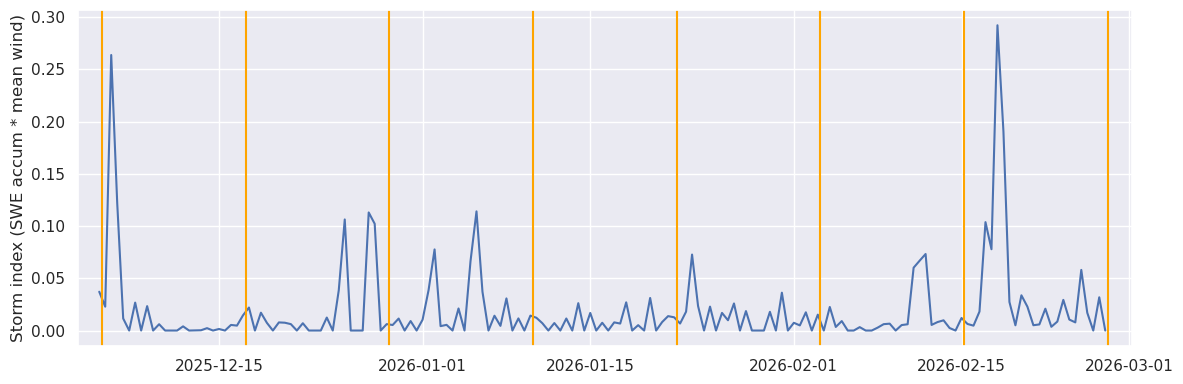

In [71]:
wind_daily = wind_dry['wind_speed'].resample(datetime='12h').mean()
swe_daily = swe_dry['swe_accum'].resample(datetime='12h').sum() 

storm_index = (wind_daily.mean(dim=['station_id']) / wind_daily.max() ) * (swe_daily.where(swe_daily > 1, 0).mean(dim=['station_id']) / swe_daily.max())

fig, ax = plt.subplots(figsize=(12, 4))

ax.plot(storm_index.datetime, storm_index)
ax.set_ylabel('Storm index (SWE accum * mean wind)')

[ax.axvline(d, c='orange') for d in unique_dates]

ax.set_xlim(dry_starts[0] - pd.Timedelta(days=2), dry_ends[-1] + pd.Timedelta(days=2))

plt.tight_layout()
plt.show()

Next, find the mean wind speed during the snow accumulation events in each date pair. An event is any 6 hour period with more than 6 mm of SWE accumulation, plus the following 24 hours. 

In [72]:
threshold = 6  # mm
freq = '12h'

swe_stns = ['schofield_pass']
wind_stns = ['CACNM', 'CASCP']

Plot the SWE accumulation and wind speed, shading the accumulation events in each date pair. 

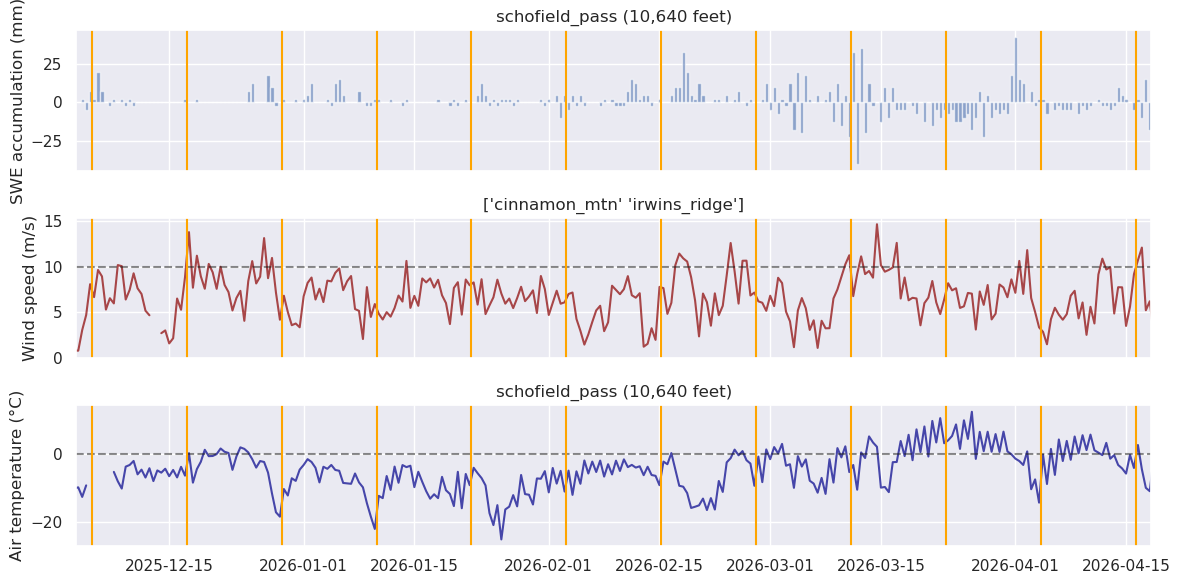

In [73]:
swe_6h = swe.sel(station_name=swe_stns)['swe_accum'].mean(dim='station_id').resample(datetime=freq).sum()
wind_6h = wind['wind_speed'].sel(station_id=wind_stns).mean(dim='station_id').resample(datetime=freq).median()
temp_6h = wind['air_temp'].sel(station_name=swe_stns).mean(dim='station_id').resample(datetime=freq).median()
events = swe_6h['datetime'].values[(swe_6h > threshold).values]

fig, axes = plt.subplots(3, 1, figsize=(12, 6), sharex=True)
(ax, ax2, ax3) = axes

ax.bar(swe_6h['datetime'], swe_6h, edgecolor=None, alpha=0.6, width=0.4)
ax.set_ylabel('SWE accumulation (mm)')
ax.set_title(f"{swe_stns[0]} (10,640 feet)")

ax2.plot(wind_6h['datetime'], wind_6h, c='darkred', alpha=0.7)
ax2.axhline(10, c='k', alpha=0.5, linestyle='--')
ax2.set_ylabel('Wind speed (m/s)')
ax2.set_title(f"{wind.station_name.loc[wind_stns].values}")

ax3.plot(temp_6h['datetime'], temp_6h, c='darkblue', alpha=0.7)
ax3.axhline(0, c='k', alpha=0.5, linestyle='--')
ax3.set_ylabel('Air temperature (°C)')
ax3.set_title(f"{swe_stns[0]} (10,640 feet)")

[a.axvline(d, c='orange') for a in axes for d in unique_dates]

# for s, e in zip(starts, ends):
#     for t in events[(events >= s) & (events <= e)]:
#         [a.axvspan(t, min(t + np.timedelta64(24, 'h'), e), alpha=0.2) for a in axes]

ax.set_xlim((starts[0] - pd.Timedelta(days=2), ends[-1] + pd.Timedelta(days=2)))

plt.tight_layout()
plt.show()

Idea: 
wind lowers coherence more on SW aspects than NE aspects. 

Label each pair as wet or dry snow, using the same cutoff as above. 

In [74]:
wet = starts > np.datetime64('2026-02-20')

Calculate the snow accumulation and wind metrics for each pair, using the same stations, threshold and frequency as above. 

In [75]:
threshold = 6  # mm
freq = '12h'
metrics = pair_metrics(swe.sel(station_name=swe_stns)['swe_accum'], 
                       wind['wind_speed'].sel(station_id=wind_stns), 
                       wind['air_temp'].sel(station_name=swe_stns),
                       starts, ends, 
                       threshold, event_freq=freq)
metrics

<xarray.Dataset> Size: 2kB
Dimensions:                   (pair: 11)
Coordinates:
  * pair                      (pair) <U17 748B '20251205_20251217' ... '20260...
Data variables: (12/15)
    swe_tot                   (pair) float64 88B 35.56 50.8 ... -43.18 -30.48
    swe_loss                  (pair) float64 88B -35.56 -22.86 ... -373.4 -185.4
    swe_max_6h                (pair) float64 88B 12.7 10.16 7.62 ... 22.86 10.16
    swe_max_12h               (pair) float64 88B 20.32 17.78 ... 43.18 10.16
    swe_max_1d                (pair) float64 88B 27.94 20.32 ... 58.42 15.24
    wind_mean                 (pair) float64 88B 6.468 8.557 ... 7.021 5.757
    ...                        ...
    wind_event_6h             (pair) float64 88B 7.72 8.762 ... 6.881 4.842
    swe_max_6h_x_wind_event   (pair) float64 88B 98.05 89.02 ... 157.3 49.19
    wind_event_12h            (pair) float64 88B 7.452 8.546 ... 7.555 6.388
    swe_max_12h_x_wind_event  (pair) float64 88B 151.4 152.0 ... 326.2 64.9
    wind_event_1d             (pair) float64 88B 7.452 8.835 ... 8.138 6.305
    swe_max_1d_x_wind_event   (pair) float64 88B 208.2 179.5 ... 475.4 96.08

Get the mean $\gamma_{snow}$ for each pair at both resolutions, and the difference between the two. 

In [76]:
cond1 = nisar_80m['canopy_2019'] < 0.6
cond2 = nisar_80m['elevation'] > 3000

cond1_20m = nisar_20m['canopy_2019'] < 0.6
cond2_20m = nisar_20m['elevation'] > 3000

In [77]:
# nisar_80m['gamma_snow_80div20'] = nisar_80m['gamma_snow_80div20'].where(nisar_80m['gamma_snow_80div20'] <= 1, np.nan)
# nisar_80m['gamma_snow'] = nisar_80m['gamma_snow'].where(nisar_80m['gamma_snow'] <= 1, np.nan)
# nisar_20m['gamma_snow'] = nisar_20m['gamma_snow'].where(nisar_20m['gamma_snow'] <= 1, np.nan)

nisar_80m['gamma_snow_80div20'] = nisar_80m['gamma_snow_80div20'].clip(min=0, max=1)
nisar_80m['gamma_snow'] = nisar_80m['gamma_snow'].clip(min=0, max=1)
nisar_20m['gamma_snow'] = nisar_20m['gamma_snow'].clip(min=0, max=1)

In [78]:
y = {
    '80 m': nisar_80m['gamma_snow'].where(cond1 & cond2).mean(dim=['x', 'y']),
    '20 m': nisar_20m['gamma_snow'].where(cond1_20m & cond2_20m).mean(dim=['x', 'y']),
    'difference': (nisar_80m['gamma_snow'] - nisar_20m['gamma_snow'].rio.reproject_match(nisar_80m, resampling=Resampling.bilinear)).where(cond1 & cond2).mean(dim=['x', 'y']),
}

Scatter each metric against mean $\gamma_{snow}$ for the 80 m grid, the 20 m grid, and the difference between them, with the wet snow pairs in red. 

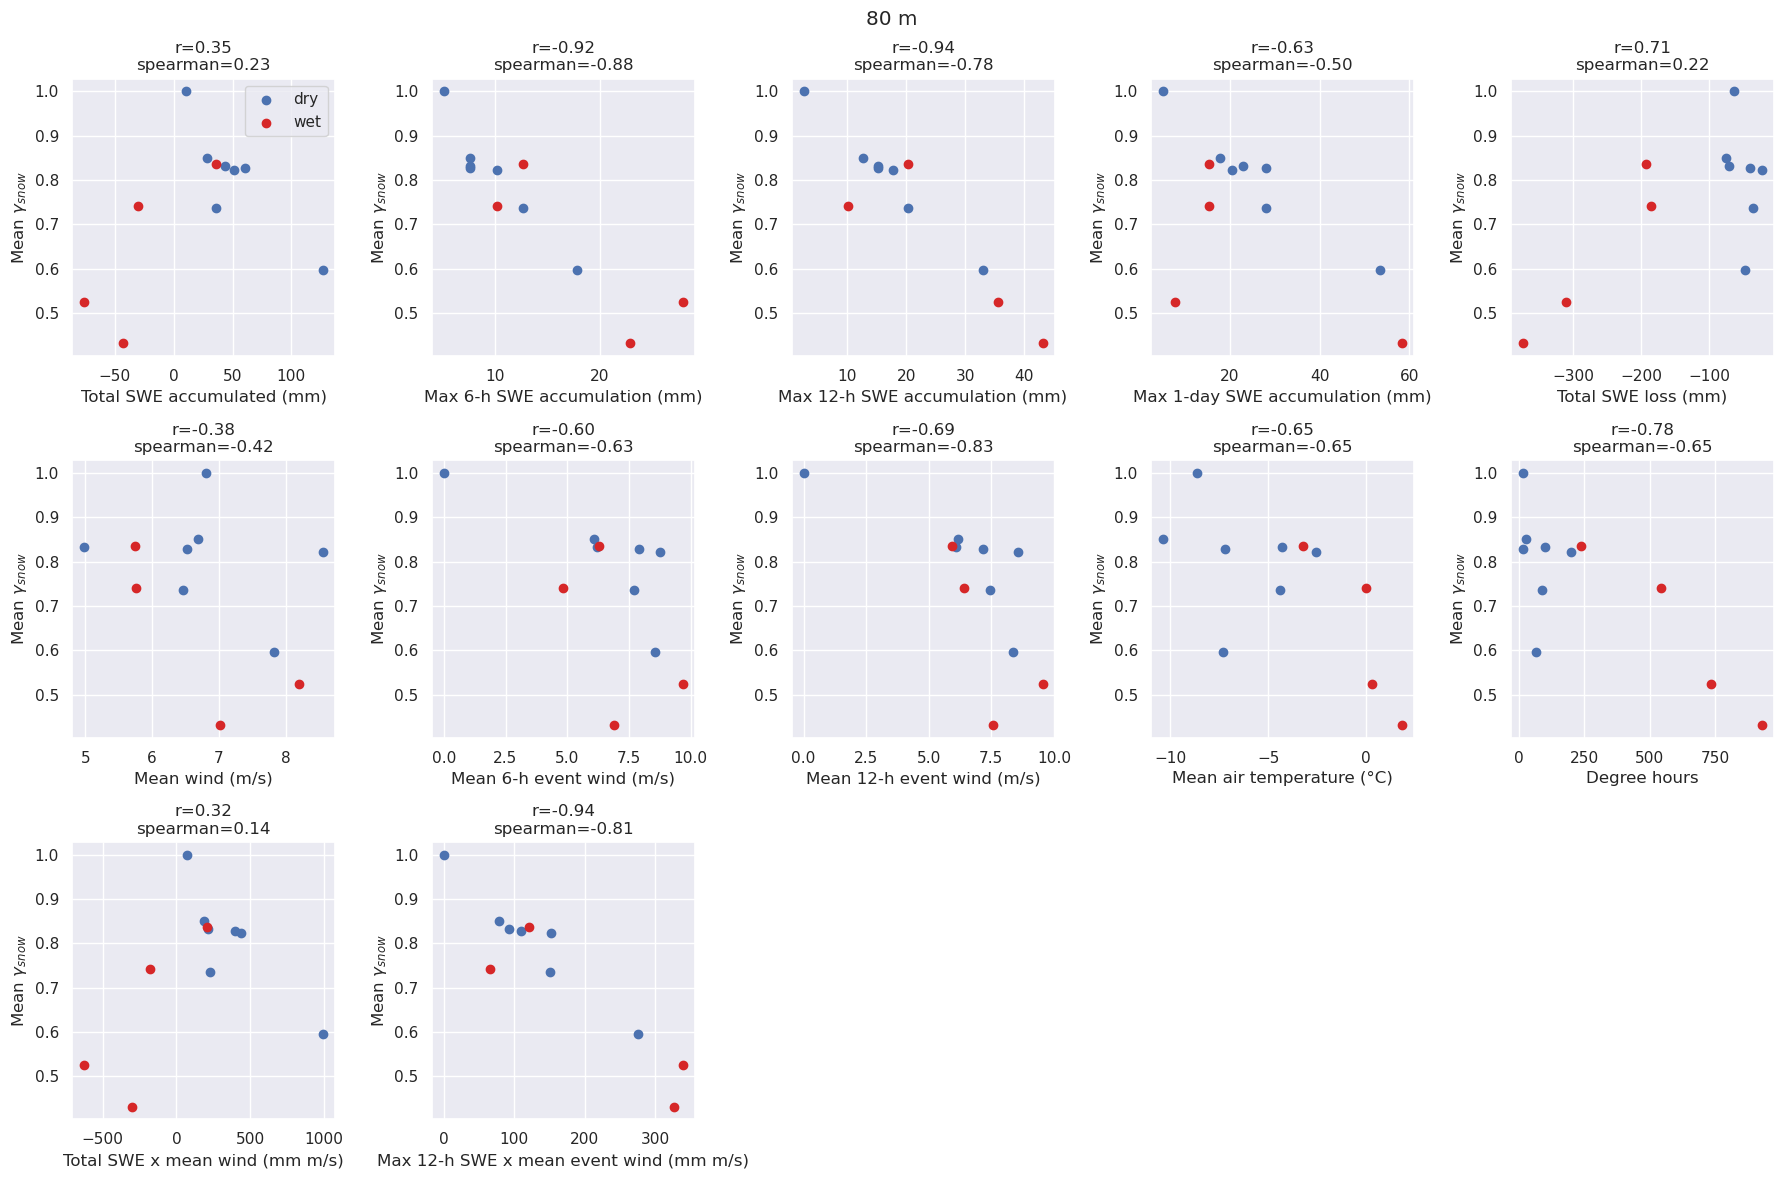

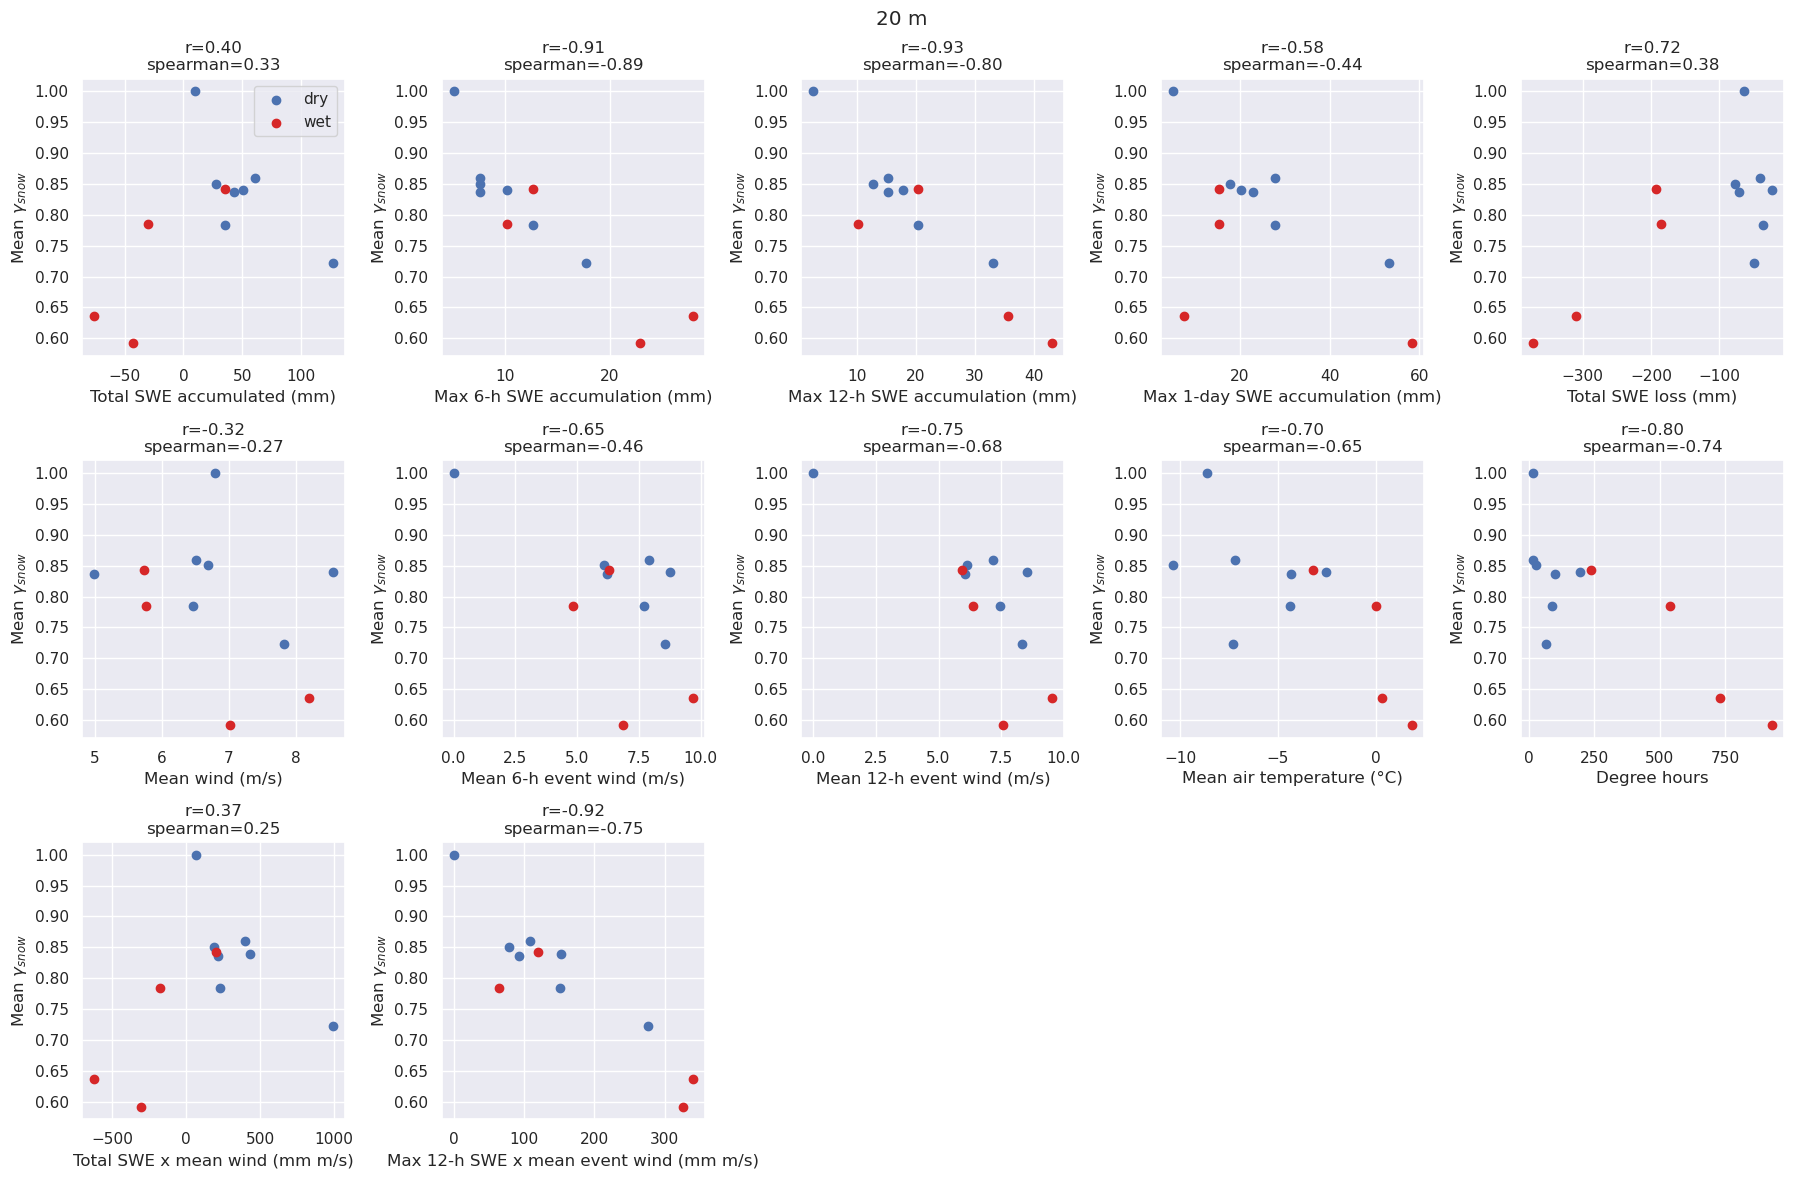

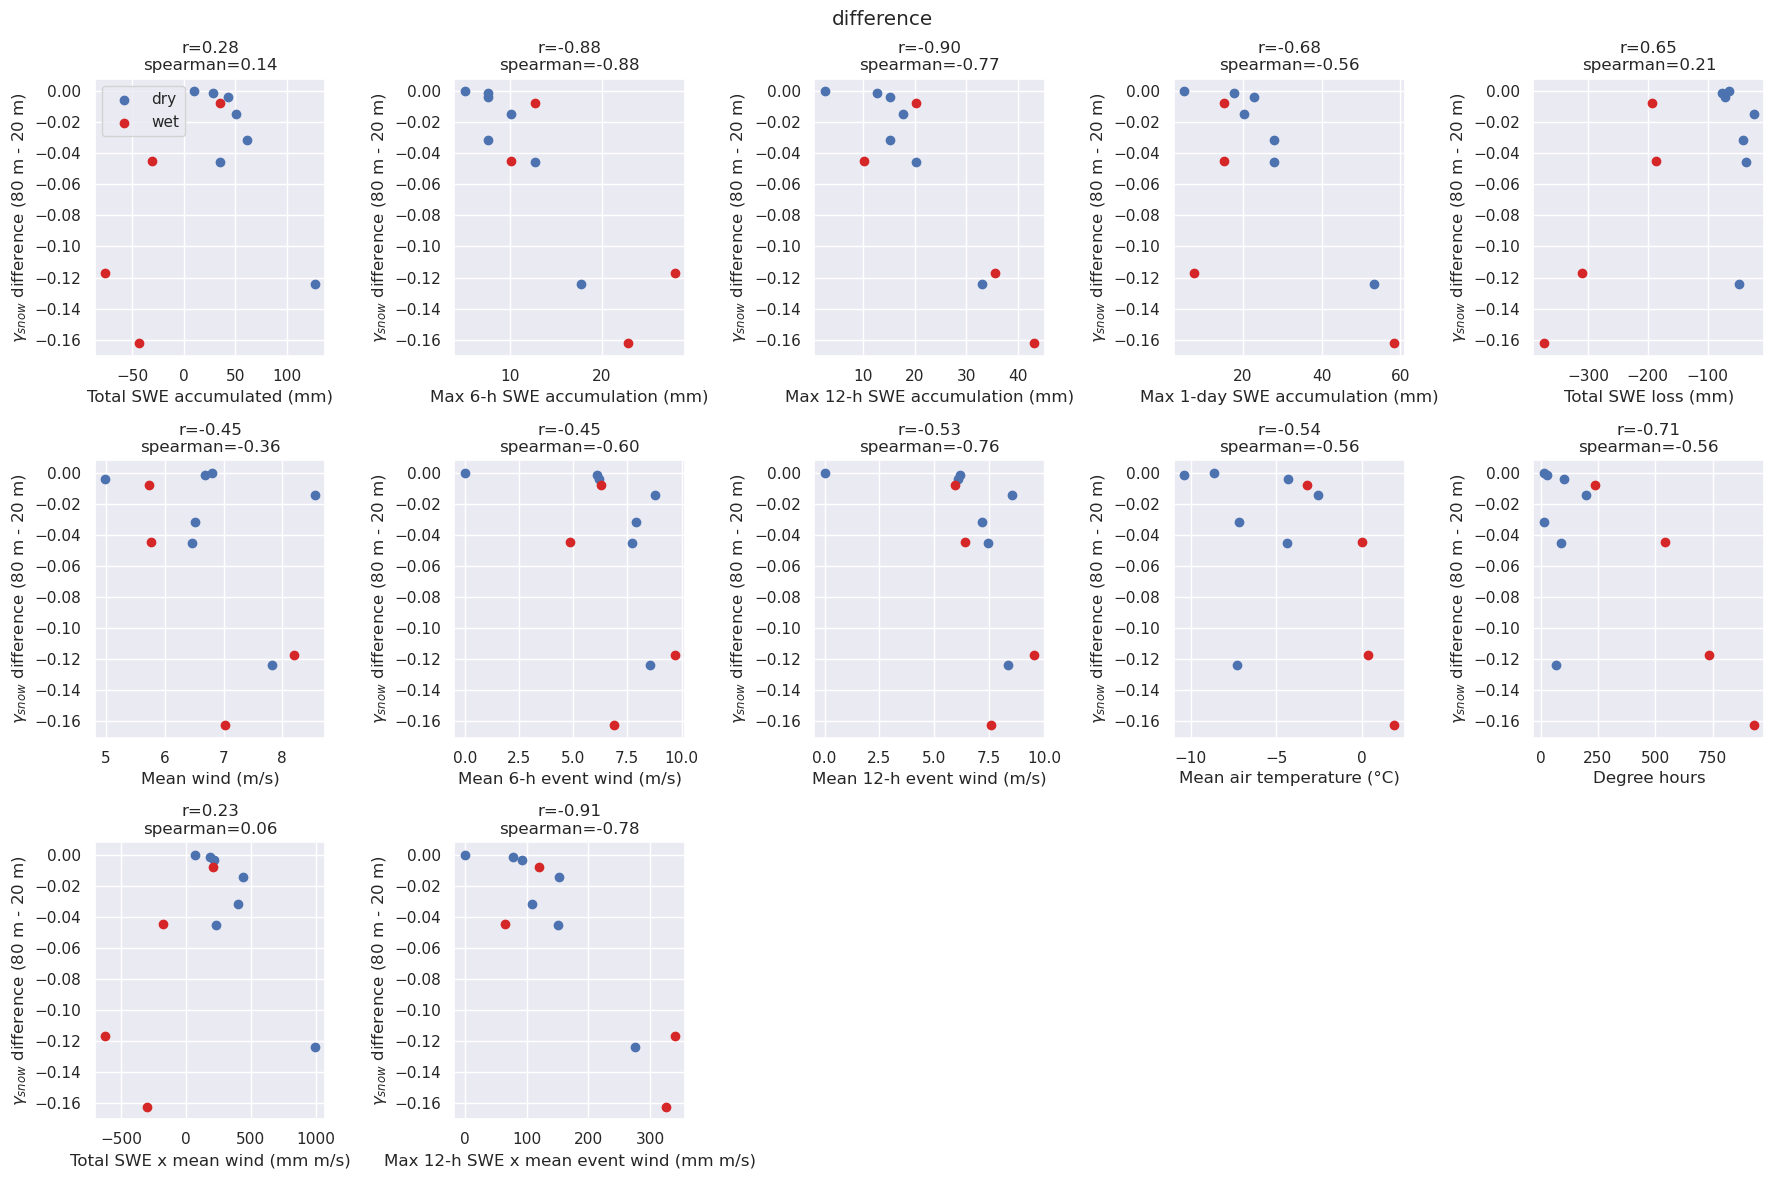

In [79]:
xlabels = {
    'swe_tot': 'Total SWE accumulated (mm)',
    'swe_max_6h': 'Max 6-h SWE accumulation (mm)',
    'swe_max_12h': 'Max 12-h SWE accumulation (mm)',
    'swe_max_1d': 'Max 1-day SWE accumulation (mm)',
    'swe_loss': 'Total SWE loss (mm)',
    'wind_mean': 'Mean wind (m/s)',
    'wind_event_6h': 'Mean 6-h event wind (m/s)',
    'wind_event_12h': 'Mean 12-h event wind (m/s)',
    'temp_mean': 'Mean air temperature (°C)',
    'degree_days': 'Degree hours',
    'swe_x_wind': 'Total SWE x mean wind (mm m/s)',
    'swe_max_12h_x_wind_event': 'Max 12-h SWE x mean event wind (mm m/s)',

}
ylabels = {
    '80 m': r'Mean $\gamma_{snow}$',
    '20 m': r'Mean $\gamma_{snow}$',
    'difference': r'$\gamma_{snow}$ difference (80 m - 20 m)',
}

for res, yvals in y.items():
    yv = yvals.values
    fig, axes = plt.subplots(3, 5, figsize=(18, 12))

    for ax, (var, xlabel) in zip(axes.flatten(), xlabels.items()):
        x = metrics[var].values
        ok = np.isfinite(x) & np.isfinite(yv)

        ax.scatter(x[~wet], yv[~wet], label='dry')
        ax.scatter(x[wet], yv[wet], c='tab:red', label='wet')
        spear_rank = pd.Series(x[ok]).rank().corr(pd.Series(yv[ok]).rank(), method='spearman')
        ax.set_title('r={:.2f}\nspearman={:.2f}'.format(np.corrcoef(x[ok], yv[ok])[0, 1], spear_rank))
        # spearman's rank correlation 
        ax.set_xlabel(xlabel)
        ax.set_ylabel(ylabels[res])

    # turn off grid for remaining axes 
    for ax in axes.flatten()[len(xlabels):]:
        ax.axis('off')

    axes[0, 0].legend()
    fig.suptitle(res)
    plt.tight_layout()
    plt.show()

In [80]:
nisar_80m


<xarray.Dataset> Size: 78MB
Dimensions:                     (y: 524, x: 410, pair: 11)
Coordinates:
  * y                           (y) float64 4kB 4.323e+06 ... 4.281e+06
  * x                           (x) float64 3kB 3.16e+05 3.16e+05 ... 3.487e+05
  * pair                        (pair) <U17 748B '20251205_20251217' ... '202...
    end                         (pair) datetime64[ns] 88B dask.array<chunksize=(11,), meta=np.ndarray>
    start                       (pair) datetime64[ns] 88B dask.array<chunksize=(11,), meta=np.ndarray>
    band                        int64 8B ...
    spatial_ref                 int64 8B ...
Data variables:
    canopy_2019                 (y, x) float32 859kB dask.array<chunksize=(262, 205), meta=np.ndarray>
    coherence                   (pair, y, x) float32 9MB dask.array<chunksize=(3, 131, 205), meta=np.ndarray>
    coherence_true              (pair, y, x) float32 9MB dask.array<chunksize=(3, 131, 205), meta=np.ndarray>
    cover_2019                  (y, x) float32 859kB dask.array<chunksize=(262, 205), meta=np.ndarray>
    elevation                   (y, x) float32 859kB dask.array<chunksize=(262, 205), meta=np.ndarray>
    gamma_snow                  (pair, y, x) float32 9MB dask.array<chunksize=(3, 131, 205), meta=np.ndarray>
    gamma_snow_80div20          (pair, y, x) float32 9MB dask.array<chunksize=(3, 131, 205), meta=np.ndarray>
    gamma_spatial               (pair, y, x) float32 9MB dask.array<chunksize=(3, 131, 205), meta=np.ndarray>
    gamma_temporal              (pair, y, x) float32 9MB dask.array<chunksize=(3, 131, 205), meta=np.ndarray>
    gamma_temporal_uncorrected  (pair, y, x) float32 9MB dask.array<chunksize=(3, 131, 205), meta=np.ndarray>
    gamma_thermal               (pair, y, x) float32 9MB dask.array<chunksize=(3, 131, 205), meta=np.ndarray>

In [81]:
to_plot = y['80 m']

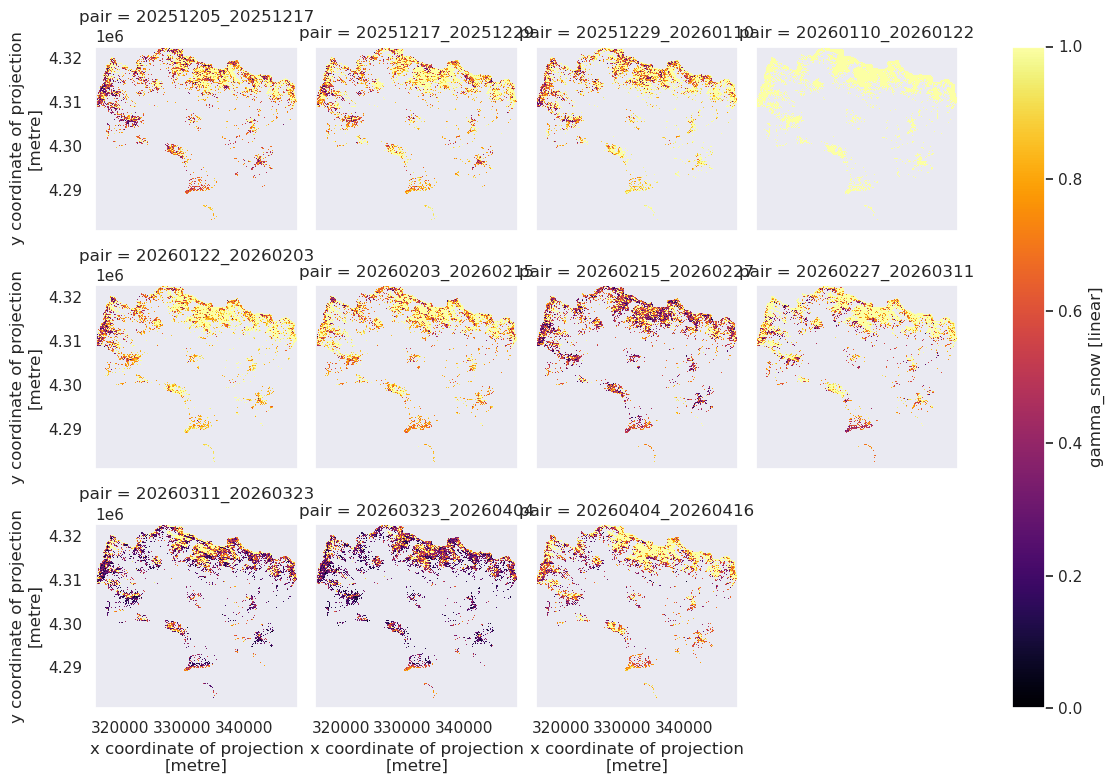

In [82]:
nisar_80m['gamma_snow'].where(cond1 & cond2).plot(col='pair', col_wrap=4, figsize=(12, 8), sharex=True, sharey=True, vmin=0, vmax=1, cmap='inferno')

/tmp/ipykernel_8692/3064245410.py:35: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
/bsuhome/julialober/miniforge3/envs/coherence_v2/lib/python3.11/site-packages/IPython/core/pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


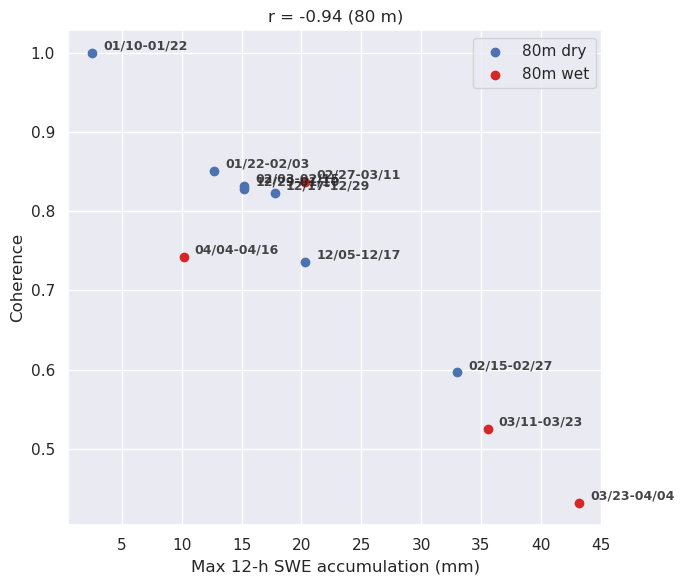

In [83]:
wind_80m = metrics['swe_max_12h']
wind_20m = metrics['swe_max_12h']

# coh_80m = nisar_80m['gamma_snow'].where(nisar_80m['elevation'] > 3500).mean(dim=['x', 'y'])
# coh_80m = y['difference']
# coh_20m = nisar_20m['gamma_snow'].mean(dim=['x', 'y'])

fig, ax = plt.subplots(figsize=(7, 6))

ax.scatter(wind_80m[~wet], to_plot[~wet], label='80m dry')
ax.scatter(wind_80m[wet], to_plot[wet], c='tab:red', label='80m wet')
# ax.scatter(wind_20m, coh_20m, c='orange', label='20 m res')

ax.set_title(f'r = {np.corrcoef(wind_80m, to_plot)[0, 1]:.2f} (80 m)')#, {np.corrcoef(wind_20m, coh_20m)[0, 1]:.2f} (20 m)')

ax.set_ylabel('Coherence')
ax.set_xlabel(f'{xlabels["swe_max_12h"]}')
ax.legend()

for (pair_label, start, end) in zip(nisar_80m.pair, starts, ends):
    ax.annotate(
        "-".join([pd.to_datetime(start).strftime('%m/%d'), 
                  pd.to_datetime(end).strftime('%m/%d')]),
        (wind_80m.sel(pair=pair_label), to_plot.sel(pair=pair_label)),
        textcoords="offset points",
        xytext=(8, 5),
        ha="left",
        va="center",
        fontsize=9,
        fontweight="semibold",
        alpha=0.85,
        zorder=5,
    )

plt.tight_layout()
plt.show()

Save the zarrs. 

In [84]:
# wind.to_zarr(data_dir + 'stations/zarrs/wind.zarr', mode="w")
# swe.to_zarr(data_dir + 'stations/zarrs/swe.zarr', mode="w")
# xr.Dataset({'storm_index': storm_by_pair, 'snow_wind_mps': snow_wind_mps}).to_zarr(data_dir + 'nisar/zarrs/storm_pairs.zarr', mode="w")
# metrics.to_zarr(data_dir + 'nisar/zarrs/pair_metrics.zarr', mode="w")